# Challenge 3 — GNN-enhanced GraphRAG

**Murphy · Southwest · 19 July 2024 · branch `challenge-3/human-ai-co-design-gnn`**

The knowledge graph and the GraphRAG layer already exist (`notebooks/03_graphrag.ipynb`).
This notebook asks one question: **does a graph neural network improve the retrieval
ranking, and can the answer be measured rather than asserted?**

The logic lives in `src/murphy/`, so nothing here is duplicated — this notebook runs it
and shows the output.

| | |
|---|---|
| `gnn_export.py` | read the Southwest subgraph from Neo4j |
| `gnn_features.py` | features, labels, temporal split, and the leakage guards |
| `gnn_model.py` | the query-aware ranker, at depth 0 and depth 1 |
| `gnn_explain.py` | the worked message-passing example and the ranking demo |
| `04_gnn_ablation.py` | the five-rung ablation |

Decisions and their evidence: `docs/challenge-3/challenge3_log.md`, entries **N1–N13**.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

from murphy.gnn_features import build
from murphy import gnn_model, gnn_explain

## 1. What was added to the knowledge graph

The graph scored flights one at a time, so **correlated failure was invisible** — five
alternatives leaving one airport in one hour do not fail independently.

`Weather` nodes were already one node per airport-hour. Adding the label `:AirportHour`
names that second role without renaming anything, and two new edge types connect each
flight to the hour it departs into and arrives into.

Nodes unchanged at 37,059; relationships 117,489 → **147,881** (37% of the Aura cap).

Crucially the **hour is part of the node's identity**, so the node cannot mix hours. An
`Airport` node would have joined a 09:00 flight to a 22:00 flight — see decision **N4**.

In [2]:
from murphy import kg
for row in kg.run('''
    MATCH (h:AirportHour)
    RETURN h.iata AS airport, h.hour_utc AS hour,
           h.n_sched_departures AS departures, h.n_sched_arrivals AS arrivals,
           h.n_sched_movements AS movements
    ORDER BY movements DESC LIMIT 5'''):
    print(f"  {row['airport']}  {str(row['hour'])[:16]}   "
          f"dep {row['departures']:>3}  arr {row['arrivals']:>3}  total {row['movements']:>3}")

  ATL  2024-07-19T07:00   dep  70  arr  69  total 139
  ATL  2024-07-19T20:00   dep  54  arr  78  total 132
  ATL  2024-07-19T08:00   dep  64  arr  60  total 124
  ATL  2024-07-19T19:00   dep  51  arr  64  total 115
  DEN  2024-07-19T20:00   dep  65  arr  48  total 113


## 2. Features, labels, and the guards

Five assertions run on every build. They are assertions rather than review notes because
each failure mode produces a *wrong answer rather than an error* — the same class as the
two Cypher bugs in decision S7.

1. No `outcome_*` property of the flight itself reaches a feature
2. An inbound leg's delay is used **only where it had actually landed** before this
   flight was due out — otherwise masked, and masked means unknown, never zero
3. The split is temporal, asserted, never random
4. Every rotation edge runs **forward in time**
5. Normalization statistics come from the training window only

In [3]:
ds = build()
for k, v in ds.summary().items():
    print(f"  {k:<18} {v:>8,}" if isinstance(v, int) else f"  {k:<18} {v:>8}")
print(f"\n  split boundary     {ds.dep_cut}")
print(f"\n  455 of 3,501 inbound legs had NOT landed by their flight's scheduled")
print(f"  departure, so their delay is masked: {int(ds.up_observed.sum()):,} remain usable.")

  flights               4,333
  train                 3,021
  test                  1,312
  late_pct               43.2
  with_upstream         3,501
  upstream_observed     3,046
  hours                 1,615
  rot_edges             3,501
  hour_edges            8,653
  airports                107

  split boundary     2024-07-19 17:50:00-05:00

  455 of 3,501 inbound legs had NOT landed by their flight's scheduled
  departure, so their delay is masked: 3,046 remain usable.


## 3. Message passing on a real rotation chain

The assignment asks to *show how neighboring nodes contribute to an updated node
embedding*. Here it is on Murphy's own graph rather than a synthetic one: one Southwest
flight, the aircraft that fed it, and the two airport-hours it touches.

Every number below is printed from the trained model.

> Building this is what exposed a defect in the model — the un-normalized convolution was
> zeroing whole embeddings through the ReLU. See decision **N12**. A code review had not
> caught it; asking the model to explain one flight did.

In [4]:
gnn_model.SEED = 7
model, _ = gnn_model.train(ds, layers=1, verbose=False)
gnn_explain.print_worked_example(gnn_explain.worked_example(model, ds))

FLIGHT  2024-07-19_WN1582_DEN_AUS  (DEN-AUS)
        arrived +49 min  <- the label, never an input

1  MESSAGE -- what the neighbors are
   inbound  2024-07-19_WN3833_ELP_DEN  (ELP-DEN)  arrived +504 min
            observable before departure
            h = [+0.441 +0.020 +0.074 +0.209 -0.163 -0.142 ...]
   hour     AUS-2024-07-19T19
            x = [+0.732 +0.564 +1.253 +0.762 -0.090 +0.220 ...]
            (n_sched_departures .. standardized)
   hour     DEN-2024-07-19T17
            x = [+2.757 +5.769 +0.703 +1.021 -0.090 +0.220 ...]
            (n_sched_departures .. standardized)

2  AGGREGATE -- mean over each relation, which is what SAGEConv sees
   rotation  [+0.441 +0.020 +0.074 +0.209 -0.163 -0.142 ...]
   hour      [+1.744 +3.166 +0.978 +0.892 -0.090 +0.220 ...]

3  UPDATE -- learned weights combine self with aggregate, then normalize
   projected      [+1.118 -7.618 -5.082 +9.500 +0.709 +9.025 ...]
   conv output    [-2.542 -25.977 -5.798 +41.740 -11.713 +59.053 ...]
   W

## 4. The ablation — five rungs, same features, same split

| Rung | What it is | Isolates |
|---|---|---|
| **G0** | stored baseline rate | the lookup table |
| **G1** | MLP, zero message-passing layers | features without structure |
| **G2a** | the shipped Cypher rule, inbound 45+ min late | structure the system already uses |
| **G2b** | congestion rule, busy departure hour | the GNN's own information, no learning |
| **G3** | GraphSAGE, one layer | structure with learning |

G1 and G3 are **one architecture at two depths**, so the comparison isolates the
structure rather than two model families.

Every learned rung is trained at five seeds. A single run at seed 7 showed the GNN
winning by +0.015 AUC; reseeding reversed it (decision **N11**).

In [5]:
%run 04_gnn_ablation.py

building features ...


  WN 4,333 labelled | train 3,021 / test 1,312 | 43.2% late | 3,501 with an inbound leg
  learned rungs trained at 5 seeds each

slack 15m: training ...


slack 45m: training ...



=== query slack 15 min (no-skill AUPRC 0.421, 78 route sets, 31 origin sets) ===
rung                     AUC    +/-  AUPRC  R@1 rt  R@3 rt  R@3 or  R@5 or  R@10 or
G0  baseline rate      0.650   --    0.557   0.298   0.908   0.199   0.304    0.551
G1  MLP                0.792  0.011  0.695   0.545   0.967   0.258   0.409    0.627
G2a rotation rule      0.659   --    0.570   0.324   0.921   0.199   0.316    0.554
G2b congestion rule    0.589   --    0.492   0.356   0.895   0.182   0.296    0.506
G3  GraphSAGE          0.791  0.016  0.688   0.517   0.962   0.245   0.398    0.634

=== query slack 45 min (no-skill AUPRC 0.749, 56 route sets, 30 origin sets) ===
rung                     AUC    +/-  AUPRC  R@1 rt  R@3 rt  R@3 or  R@5 or  R@10 or
G0  baseline rate      0.632   --    0.837   0.347   0.868   0.158   0.260    0.491
G1  MLP                0.825  0.015  0.917   0.415   0.946   0.176   0.293    0.524
G2a rotation rule      0.623   --    0.834   0.347   0.859   0.155   0.262    0.

## 5. GNN-enhanced ranking, against the rule that ships today

One traveler's question, the candidates ordered by each method, with what actually
happened beside them.

In [6]:
demo = gnn_explain.ranking_demo(model, ds, slack=15.0, k=5)
gnn_explain.print_ranking_demo(demo)

QUESTION  "Which flights out of DEN this evening will arrive within 15 minutes of schedule?"
          110 candidates in the test window, 31 actually did

GNN ranking (G3)  --  3 of top 5 were right  |  110 distinct scores across 110 candidates
   flight                        route         score  inbound late  arrived
 ok 2024-07-19_WN2557_DEN_PHX     DEN-PHX     0.92721         False     +12m
    2024-07-19_WN1969_DEN_SLC     DEN-SLC     0.92310         False     +31m
    2024-07-19_WN110_DEN_OKC      DEN-OKC     0.92276         False     +38m
 ok 2024-07-19_WN2678_DEN_SFO     DEN-SFO     0.91997         False     -14m
 ok 2024-07-19_WN2761_DEN_LGB     DEN-LGB     0.91740         False     -10m

Shipped rule (G2a)  --  5 of top 5 were right  |  104 distinct scores across 110 candidates
   flight                        route         score  inbound late  arrived
 ok 2024-07-19_WN4433_DEN_SAN     DEN-SAN    -0.00275         False     -10m
 ok 2024-07-19_WN4790_DEN_MSP     DEN-MSP    -0.

### The evidence behind the top-ranked flight

The GNN score decides **where to look**. It is never the answer. The cited evidence
stays the observed rotation chain, retrieved from the graph by parameterized Cypher —
`Derived` chooses, `Observed` is quoted.

In [7]:
top = demo["gnn"][0]["flight_id"]
path = gnn_explain.cited_path(top)
print(f"cited rotation chain for {top}:\n")
for leg, delay in zip(path["chain"], path["delays"]):
    print(f"   {leg:<34} arrived {delay:+}m")

cited rotation chain for 2024-07-19_WN2557_DEN_PHX:

   2024-07-19_WN2557_BNA_MDW          arrived +27m
   2024-07-19_WN2557_MDW_TUL          arrived +17m
   2024-07-19_WN2557_TUL_DEN          arrived -23m
   2024-07-19_WN2557_DEN_PHX          arrived +12m


## 6. What the measurements say

**Learning beats the rules decisively.** G1 at 0.792 AUC against the shipped rotation
rule at 0.659 and the congestion rule at 0.589. The graph's information is worth more
than the hand-set thresholds currently extracting it — a result for Murphy independent
of any GNN.

**Structure adds nothing on top.** G3 at 0.791 ± 0.016 against G1 at 0.792 ± 0.011,
indistinguishable. Under the lecture's own decision rule, the GNN is not kept.

**And the reason is measurable.** Removing the inbound-delay feature collapses both
models from 0.79 to ~0.54 — barely above chance — and the graph does not recover it.

`outcome_*` properties are excluded from node features by the project's standing rule,
so an inbound flight's vector carries **no delay information at all**. There is nothing
delay-related on the graph for message passing to propagate.

> **The provenance discipline that makes Murphy's forecasts trustworthy is exactly what
> leaves the GNN nothing to propagate.** That is an argument for giving the graph
> structural signals that are not outcomes — congestion propagating *between* airports,
> two-leg rotation chains, connection feasibility — not for relaxing the rule.

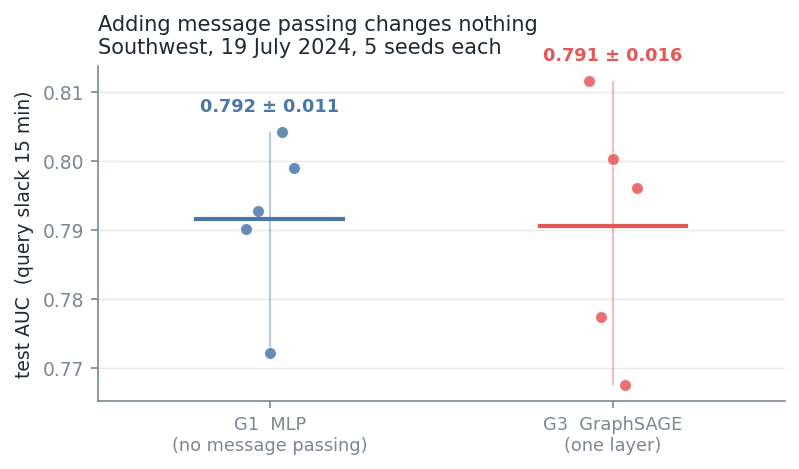

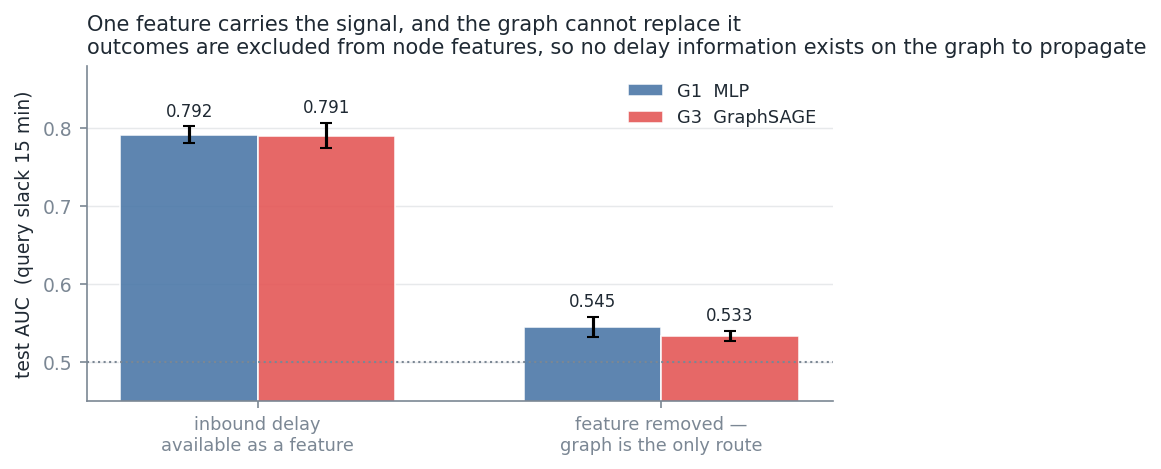

In [8]:
from IPython.display import Image, display
display(Image("../docs/challenge-3/figures/gnn_seed_spread.png"))
display(Image("../docs/challenge-3/figures/gnn_feature_ablation.png"))